# Monte Carlo del modelo de compra (Fase 1) — Entregable 2

Genera los escenarios de plantas existentes $X_{e,p}$ y de plantas establecidas $Z_{e,p}$ y evalúa el costo esperado
$c_e\,q_{e,p} + h_e\,\mathbb{E}[F_{e,p}]$, con $F_{e,p}=\max\{0,\;D_{e,p}-X_{e,p}-Z_{e,p}\}$.

**Supuestos de esta versión**

| Elemento | Modelo |
|---|---|
| $X_{e,p}$ (modelo B, error de registro) | $X_{e,p}\sim\text{Bin}(x_{e,p},\,1-0.05)$: cada planta registrada deja de existir con prob. 5 % |
| $Z_{e,p}$ (secuencial) | $Z=Z^I+Z^R$, con $Z^I\sim\text{Bin}(q^I,S_e)$, muertas $=q^I-Z^I$ y $Z^R\sim\text{Bin}(\min\{q^R,\text{muertas}\},S_e)$ |
| $S_e$ | supervivencia a 2 años (2021→2023) del monitoreo del socioformador (`parametros_especies.csv`) |
| $c_e$, $h_e$ | $c_e$ de la tabla de costos; $h_e = 1.1\,c_e$ |
| Presupuesto | \$12,500 por ha |
| $\lvert N_p\rvert$ | **placeholder**: $\text{round}(658\,A_p)$, hasta tener la malla real |
| Independencia | especies y polígonos independientes (no afecta el costo esperado, que es lineal en las esperanzas marginales) |

**Números aleatorios comunes:** se generan una sola vez un uniforme $U^1$ y otro $U^2$ por (escenario, especie, polígono) y $Z$ se obtiene por inversión de la CDF binomial. Así $Z$ es monótona en $q^I$ y $q^R$ y las comparaciones entre compras distintas no dependen del ruido de la simulación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---------------- CONFIGURACIÓN ----------------
N        = 10_000     # escenarios Monte Carlo
SEED     = 2026
ERR_REG  = 0.05       # modelo B: prob. de que una planta registrada ya no exista
H_FACTOR = 1.1        # h_e = H_FACTOR * c_e
B_HA     = 12_500     # presupuesto por hectárea ($)
PTOS_HA  = 658        # PLACEHOLDER: puntos de malla por ha, |N_p| = round(658 * A_p)
SUPERV   = 'sobrev_2023'   # supervivencia a 2 años; 'sobrev_2022' = a 1 año

# ---------------- DATOS ----------------
datos = pd.read_csv('datos_limpios.csv')
par   = pd.read_csv('parametros_especies.csv').set_index('especie')
esp   = list(par.index)
x     = datos.pivot(index='especie', columns='poligono', values='plantas').loc[esp]
A     = datos.drop_duplicates('poligono').set_index('poligono')['area_ha'].sort_index()
x     = x[A.index]
E_, P_ = x.shape

d = par['meta_plantas_ha'].values.astype(float)
c = par['costo_c'].values.astype(float)
h = H_FACTOR * c
S = par[SUPERV].values.astype(float)
D = np.outer(d, A.values)                      # D_{e,p} = d_e * A_p
Np = np.round(PTOS_HA * A.values).astype(int)  # puntos de malla por polígono
par.assign(h_e=h)

,meta_plantas_ha,costo_c,sobrev_2022,sobrev_2023,h_e
especie,,,,,
Agave lechuguilla,42.0,26.0,0.9435,0.9265,28.60
Agave salmiana,196.0,26.0,0.9587,0.9082,28.60
Agave scabra,42.0,26.0,0.8245,0.7453,28.60
Agave striata,42.0,26.0,0.9517,0.9138,28.60
Opuntia cantabrigiensis,49.0,18.0,0.9272,0.8287,19.80
Opuntia engelmannii,38.0,21.0,0.8986,0.8194,23.10
Opuntia robusta,73.0,18.0,0.9576,0.9198,19.80
Opuntia streptacantha,64.0,18.0,0.8860,0.8525,19.80
Prosopis laevigata,86.0,26.5,0.8214,0.8179,29.15


## 1. Escenarios de plantas existentes $X_{e,p}$ (modelo B) y números aleatorios comunes

In [2]:
rng = np.random.default_rng(SEED)
X  = rng.binomial(x.values, 1 - ERR_REG, size=(N, E_, P_))          # (N, 10, 30)
eps = 1e-12
U1 = np.clip(rng.random((N, E_, P_)), eps, 1 - eps)                 # para Z^I
U2 = np.clip(rng.random((N, E_, P_)), eps, 1 - eps)                 # para Z^R

# Puntos libres de la malla, truncados en 0
L = np.maximum(Np[None, :] - X.sum(axis=1), 0)                      # (N, 30)
EL = L.mean(axis=0)

print('Forma de X:', X.shape)
print('E[X] / x observado (debe ser ≈ 0.95):', round(X.mean(0).sum() / x.values.sum(), 4))
print('E[L_p] (primeros 5 polígonos):', EL[:5].round(1), '| |N_p|:', Np[:5])

Forma de X: (10000, 10, 30)
E[X] / x observado (debe ser ≈ 0.95): 0.95
E[L_p] (primeros 5 polígonos): [ 685.3 3548.1 3632.   734.1 4311.1] | |N_p|: [ 842 4369 4448  908 5264]


## 2. Plantas establecidas $Z_{e,p}$ (secuencial) y costo esperado

In [3]:
def Z_sec(qI, qR, S_e, u1, u2):
    """Z secuencial por inversión de la CDF binomial (números comunes).
    qI, qR: enteros (o arreglos que broadcastean con u1, u2)."""
    ZI  = stats.binom.ppf(u1, qI, S_e)
    nR  = np.minimum(qR, qI - ZI)          # reposición: solo en cepas donde murió una planta
    ZR  = stats.binom.ppf(u2, nR, S_e)
    return ZI + ZR

def curva_costo(e, p, qI, qR=0, n=None):
    """Costo esperado c*q + h*E[F] para la especie e y el polígono p (índices 0-based).
    qI puede ser un arreglo (malla de compras); qR escalar o del mismo tamaño.
    Devuelve (costo, E[F], error estándar del costo)."""
    n = n or N
    qI = np.atleast_1d(qI).astype(int)
    qR = np.broadcast_to(np.asarray(qR, dtype=int), qI.shape)
    z  = Z_sec(qI[None, :], qR[None, :], S[e], U1[:n, e, p][:, None], U2[:n, e, p][:, None])
    F  = np.maximum(0.0, D[e, p] - X[:n, e, p][:, None] - z)
    J  = c[e] * (qI + qR)[None, :] + h[e] * F
    return J.mean(0), F.mean(0), J.std(0, ddof=1) / np.sqrt(n)

def evaluar_politica(qI, qR):
    """Evalúa una compra completa. qI, qR: arreglos (10, 30) de enteros.
    Devuelve un DataFrame por polígono con compra, costo, faltante esperado y error estándar."""
    qI = np.asarray(qI, dtype=int)[None]; qR = np.asarray(qR, dtype=int)[None]
    Z  = Z_sec(qI, qR, S[None, :, None], U1, U2)                 # (N, 10, 30)
    F  = np.maximum(0.0, D[None] - X - Z)                        # (N, 10, 30)
    compra  = (c[:, None] * (qI[0] + qR[0])).sum(0)              # costo de compra por polígono
    penal   = h[None, :, None] * F
    total   = compra[None, :] + penal.sum(1)                     # (N, 30)
    return pd.DataFrame({
        'area_ha': A.values,
        'costo_compra': compra,
        'presupuesto': B_HA * A.values,
        'E_faltante_plantas': F.sum(1).mean(0),
        'costo_total_esp': total.mean(0),
        'EE_costo_total': total.std(0, ddof=1) / np.sqrt(N),
    }, index=A.index)

## 3. Verificaciones de la simulación

In [4]:
# (a) E[Z] simulada vs. valor exacto con la pmf binomial
e, p, qI_t, qR_t = 1, 1, 400, 60          # Agave salmiana, polígono 2
z   = Z_sec(qI_t, qR_t, S[e], U1[:, e, p], U2[:, e, p])
k   = np.arange(qI_t + 1)
pmf = stats.binom.pmf(k, qI_t, S[e])
exacto = S[e] * qI_t + S[e] * (pmf * np.minimum(qR_t, qI_t - k)).sum()
print(f'E[Z] exacta = {exacto:.3f} | simulada = {z.mean():.3f} ± {z.std(ddof=1)/np.sqrt(N):.3f} (EE)')

# (b) Z monótona en qI y qR (números comunes) y Z <= qI + qR
g = np.arange(0, 301, 5)
z_I = Z_sec(g[None, :], 40, S[e], U1[:, e, p][:, None], U2[:, e, p][:, None])
z_R = Z_sec(100, g[None, :], S[e], U1[:, e, p][:, None], U2[:, e, p][:, None])
print('monótona en qI:', bool((np.diff(z_I, axis=1) >= 0).all()),
      '| monótona en qR:', bool((np.diff(z_R, axis=1) >= 0).all()),
      '| Z <= q:', bool((z_I <= g[None, :] + 40).all()))

# (c) X: media y varianza del modelo B para un par (e, p)
xo = x.values[e, p]
print(f'x observado = {xo} | E[X] = {X[:, e, p].mean():.2f} (teórico {xo*(1-ERR_REG):.2f}) | '
      f'Var[X] = {X[:, e, p].var():.2f} (teórico {xo*ERR_REG*(1-ERR_REG):.2f})')

E[Z] exacta = 396.629 | simulada = 396.648 ± 0.018 (EE)


monótona en qI: True | monótona en qR: True | Z <= q: True
x observado = 263 | E[X] = 249.84 (teórico 249.85) | Var[X] = 12.67 (teórico 12.49)


## 4. Diagnóstico de los parámetros

Cada planta comprada aporta como máximo $S_e$ plantas establecidas en esperanza, así que reduce $h_e\,\mathbb{E}[F]$ en a lo más $h_e S_e$ y cuesta $c_e$. Si $S_e < c_e/h_e$ comprar nunca reduce el costo esperado y el óptimo de la función objetivo (1) es $q_e=0$, sin importar las restricciones (3)–(6), que son cotas superiores.

In [5]:
EX_ha = X.sum(axis=2).mean(axis=0) / A.sum()          # E[X] por ha (agregado)
diag = pd.DataFrame({
    'meta_ha': d, 'E[X]_ha': EX_ha.round(2), 'brecha_ha': np.maximum(d - EX_ha, 0).round(1),
    'S_e': S, 'c_e': c, 'h_e': h.round(2),
    'S_umbral = c/h': (c / h).round(4),
    '¿comprar conviene?': S > c / h,
}, index=esp)
display(diag)

costo_brecha = (np.maximum(d - EX_ha, 0) * c).sum()
print(f'Costo por ha de cubrir la brecha esperada si todo sobreviviera : ${costo_brecha:,.0f}')
print(f'Costo por ha de cubrirla con la supervivencia S_e             : ${(np.maximum(d-EX_ha,0)*c/S).sum():,.0f}')
print(f'Presupuesto por ha                                            : ${B_HA:,.0f}')
print('h_e mínimo para que comprar convenga en cada especie (h > c/S):')
print((c / S).round(2), '→ factor sobre c_e:', (1 / S).round(3))

,meta_ha,E[X]_ha,brecha_ha,S_e,c_e,h_e,S_umbral = c/h,¿comprar conviene?
Agave lechuguilla,42.0,7.74,34.3,0.9265,26.0,28.60,0.9091,True
Agave salmiana,196.0,36.11,159.9,0.9082,26.0,28.60,0.9091,False
Agave scabra,42.0,7.59,34.4,0.7453,26.0,28.60,0.9091,False
Agave striata,42.0,7.29,34.7,0.9138,26.0,28.60,0.9091,True
Opuntia cantabrigiensis,49.0,9.51,39.5,0.8287,18.0,19.80,0.9091,False
Opuntia engelmannii,38.0,7.57,30.4,0.8194,21.0,23.10,0.9091,False
Opuntia robusta,73.0,14.26,58.7,0.9198,18.0,19.80,0.9091,True
Opuntia streptacantha,64.0,11.88,52.1,0.8525,18.0,19.80,0.9091,False
Prosopis laevigata,86.0,15.67,70.3,0.8179,26.5,29.15,0.9091,False
Yucca filifera,26.0,4.73,21.3,0.7263,26.0,28.60,0.9091,False


Costo por ha de cubrir la brecha esperada si todo sobreviviera : $12,607
Costo por ha de cubrirla con la supervivencia S_e             : $14,655
Presupuesto por ha                                            : $12,500
h_e mínimo para que comprar convenga en cada especie (h > c/S):
[28.06 28.63 34.89 28.45 21.72 25.63 19.57 21.11 32.4  35.8 ] → factor sobre c_e: [1.079 1.101 1.342 1.094 1.207 1.22  1.087 1.173 1.223 1.377]


## 5. Curvas de costo esperado por especie (un polígono de ejemplo)
Costo esperado $c\,q + h\,\mathbb{E}[F]$ contra la compra inicial $q^I$ (con $q^R=0$), usando los primeros 2,000 escenarios para que sea rápido.

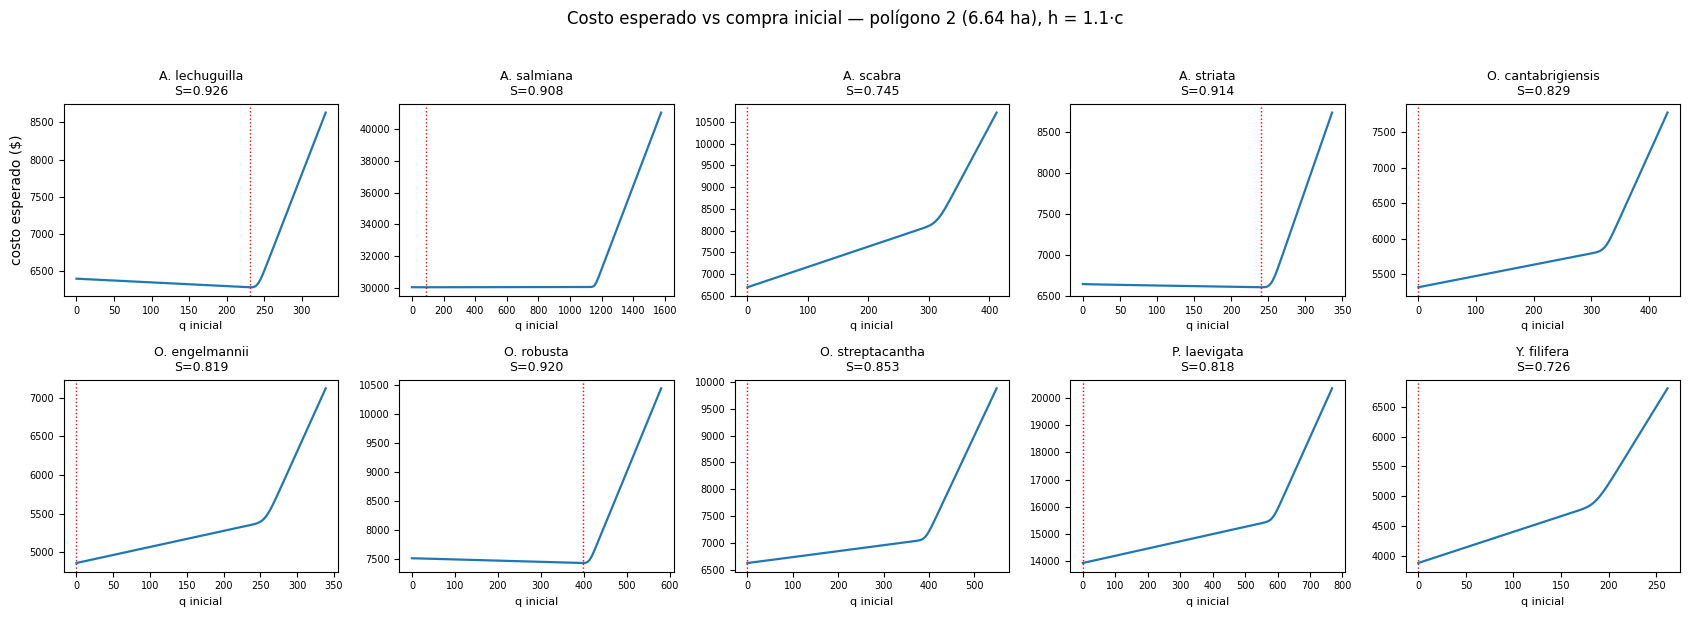

,especie,meta_D,q*_sin_restr,J(0),J(q*),S>c/h
0,Agave lechuguilla,278.88,231,6399.907800,6285.021600,True
1,Agave salmiana,1301.44,92,30073.829500,30071.980900,False
2,Agave scabra,278.88,0,6698.248700,6698.248700,False
3,Agave striata,278.88,240,6644.166100,6605.629264,True
4,Opuntia cantabrigiensis,325.36,0,5313.745800,5313.745800,False
5,Opuntia engelmannii,252.32,0,4862.711700,4862.711700,False
6,Opuntia robusta,484.72,399,7509.417300,7427.969064,True
7,Opuntia streptacantha,424.96,0,6626.505600,6626.505600,False
8,Prosopis laevigata,571.04,0,13931.907275,13931.907275,False
9,Yucca filifera,172.64,0,3878.803500,3878.803500,False


In [6]:
P_DEMO = 1                         # polígono 2 (índice 0-based)
n_demo = 2_000
res = []
fig, axs = plt.subplots(2, 5, figsize=(17, 6), sharey=False)
for e, ax in zip(range(E_), axs.ravel()):
    qmax = int(np.ceil(1.1 * D[e, P_DEMO] / S[e]))
    grid = np.unique(np.linspace(0, qmax, 120).astype(int))
    J, EF, se = curva_costo(e, P_DEMO, grid, 0, n=n_demo)
    i = J.argmin()
    res.append((esp[e], D[e, P_DEMO], grid[i], J[0], J[i], bool(S[e] > c[e]/h[e])))
    ax.plot(grid, J, lw=1.6); ax.axvline(grid[i], color='r', ls=':', lw=1)
    ax.set_title(f'{esp[e].split()[0][0]}. {esp[e].split()[1]}\nS={S[e]:.3f}', fontsize=9)
    ax.set_xlabel('q inicial', fontsize=8); ax.tick_params(labelsize=7)
axs[0, 0].set_ylabel('costo esperado ($)')
plt.suptitle(f'Costo esperado vs compra inicial — polígono {A.index[P_DEMO]} ({A.values[P_DEMO]} ha), h = {H_FACTOR}·c', y=1.02)
plt.tight_layout(); plt.show()
pd.DataFrame(res, columns=['especie','meta_D','q*_sin_restr','J(0)','J(q*)','S>c/h'])

## 6. Ejemplo de evaluación de una política completa

Política **ingenua** solo para probar la maquinaria (no es la solución del modelo): comprar para cubrir la brecha esperada, $q^I=\lceil\max(0,D-\mathbb{E}[X])/S\rceil$, y reposición igual a las muertas esperadas, $q^R=\lceil(1-S)\,q^I\rceil$. Ignora presupuesto y restricciones (4)–(6).

In [7]:
EX = X.mean(axis=0)                                              # (10, 30)
qI0 = np.ceil(np.maximum(D - EX, 0) / S[:, None]).astype(int)
qR0 = np.ceil((1 - S[:, None]) * qI0).astype(int)
ev = evaluar_politica(qI0, qR0)
ev['excede_presupuesto'] = ev.costo_compra > ev.presupuesto
display(ev.round(1).head(8))
print('Polígonos que exceden el presupuesto:', int(ev.excede_presupuesto.sum()), 'de', P_)
print(f'Costo de compra total: ${ev.costo_compra.sum():,.0f} vs presupuesto total ${ev.presupuesto.sum():,.0f}')
print(f'Faltante esperado total: {ev.E_faltante_plantas.sum():.0f} plantas de {D.sum():.0f} de meta ({100*ev.E_faltante_plantas.sum()/D.sum():.1f} %)')

,area_ha,costo_compra,presupuesto,E_faltante_plantas,costo_total_esp,EE_costo_total,excede_presupuesto
poligono,,,,,,,
1,1.3,21538.0,16000.0,0.1,21540.9,0.1,True
2,6.6,111088.0,83000.0,0.0,111088.0,0.0,True
3,6.8,113492.0,84500.0,0.0,113492.0,0.0,True
4,1.4,23067.5,17250.0,0.1,23069.2,0.1,True
5,8.0,134972.0,100000.0,0.0,134972.0,0.0,True
6,7.8,130095.0,97750.0,0.0,130095.0,0.0,True
7,5.5,92500.5,69125.0,0.0,92500.5,0.0,True
8,5.6,93453.5,70500.0,0.0,93453.5,0.0,True


Polígonos que exceden el presupuesto: 30 de 30
Costo de compra total: $3,064,157 vs presupuesto total $2,287,625
Faltante esperado total: 0 plantas de 120421 de meta (0.0 %)
